In [1]:
import pandas as pd

df = pd.read_csv('/content/BBMP_Ward_Clustering_Results.csv')

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (198, 30)


,Ward_No,Ward Name,BBMP Zone Name,Assembly Constituency Name,MP Constituency,Population (2011),Area (sq km),Households # (Census 2011),Road Length (kms),Lakes #,...,Streetlights #,Police stn,BBMP Division,BBMP Sub Division,Population density 2011 (persons / sq km),Decadal popn growth rate % 2011/2001,Decadal Households growth rate 2011/2001 %,Lake name,Bus routes #,Cluster
0,1.0,Kempegowda Ward,Yelahanka,Yelahanka,Chikballapur,34783,10.9,8647,86,2,...,2379,Yelahanka,Yelahanka,Yelahanka,"3,182",59.10%,72.60%,"Shivanahalli,Yelahanka",136,0
1,2.0,Chowdeswari Ward,Yelahanka,Yelahanka,Chikballapur,36602,6.5,9506,72,2,...,2508,NaN,Yelahanka,Yelahanka,"5,635",86.50%,111.00%,"Puttenahalli,Harohalli",81,0
2,3.0,Atturu,Yelahanka,Yelahanka,Chikballapur,58129,8.8,14605,169,2,...,4227,Yelahanka Setellite Town,Yelahanka,Yelahanka,"6,606",142.00%,171.30%,"Chikkabettahalli,Attur",106,2
3,4.0,Yelahanka Satellite Town,Yelahanka,Yelahanka,Chikballapur,41986,4.6,10583,86,2,...,3626,"Yelahanka, Yelahanka New Town",Yelahanka,Yelahanka,"9,224",62.90%,70.30%,"Shivanahalli,Allalasandra",158,0
4,5.0,Jakkuru,Yelahanka,Byatarayanapura,Bangalore North,52025,23.5,12387,349,10,...,4351,Sampigehalli,Byatarayanapura,Byatarayanapura,"2,215",148.20%,168.80%,"Venkateshapura,Chokkanahalli,Jakkuru - Sampige...",50,2


In [2]:
print(df.columns.tolist())
print(df.info())

['Ward_No', 'Ward Name', 'BBMP Zone Name', 'Assembly Constituency Name', 'MP Constituency', 'Population (2011)', 'Area (sq km)', 'Households # (Census 2011)', 'Road Length (kms)', 'Lakes #', 'Lake area (sq m)', 'Parks #', 'Park area (sq m)', 'Playgrounds #', 'Playground area (sq m)', 'Govt Schools #', 'Police Stations #', 'Fire stations #', 'Bus Stops #', 'BMTC TTMC #', 'Streetlights #', 'Police stn', 'BBMP Division', 'BBMP Sub Division', 'Population density 2011 (persons / sq km)', 'Decadal popn growth rate % 2011/2001', 'Decadal Households growth rate 2011/2001 %', 'Lake name', 'Bus routes #', 'Cluster']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 198 entries, 0 to 197
Data columns (total 30 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   Ward_No                                     198 non-null    float64
 1   Ward Name                                   198 non-null 

In [3]:
print("Number of wards in each cluster:")
print(df['Cluster'].value_counts().sort_index())

Number of wards in each cluster:
Cluster
0    166
1     11
2     21
Name: count, dtype: int64


In [4]:
print("Available columns:")
print(df.columns.tolist())

Available columns:
['Ward_No', 'Ward Name', 'BBMP Zone Name', 'Assembly Constituency Name', 'MP Constituency', 'Population (2011)', 'Area (sq km)', 'Households # (Census 2011)', 'Road Length (kms)', 'Lakes #', 'Lake area (sq m)', 'Parks #', 'Park area (sq m)', 'Playgrounds #', 'Playground area (sq m)', 'Govt Schools #', 'Police Stations #', 'Fire stations #', 'Bus Stops #', 'BMTC TTMC #', 'Streetlights #', 'Police stn', 'BBMP Division', 'BBMP Sub Division', 'Population density 2011 (persons / sq km)', 'Decadal popn growth rate % 2011/2001', 'Decadal Households growth rate 2011/2001 %', 'Lake name', 'Bus routes #', 'Cluster']


In [5]:
print("Missing ward names:", df['Ward Name'].isna().sum())
print("Duplicate ward numbers:", df['Ward_No'].duplicated().sum())
print("Unique wards:", df['Ward_No'].nunique())

Missing ward names: 0
Duplicate ward numbers: 0
Unique wards: 198


In [6]:
!pip install plotly

In [7]:
import plotly.express as px
import plotly.graph_objects as go

print("Plotly imported successfully!")

Plotly imported successfully!


In [8]:
cluster_counts = df['Cluster'].value_counts().sort_index().reset_index()
cluster_counts.columns = ['Cluster', 'Number of Wards']

fig = px.bar(
    cluster_counts,
    x='Cluster',
    y='Number of Wards',
    title='Distribution of Bengaluru Wards Across 3 Clusters',
    text='Number of Wards',
    color='Cluster'
)

fig.update_layout(
    xaxis_title='Cluster Group',
    yaxis_title='Number of Wards',
    template='plotly_white'
)

fig.show()

In [9]:
facility_avg = df.groupby('Cluster')[
    ['Parks #', 'Lakes #', 'Govt Schools #', 'Playgrounds #']
].mean().round(2).reset_index()

facility_avg

,Cluster,Parks #,Lakes #,Govt Schools #,Playgrounds #
0,0,8.82,0.48,3.08,1.67
1,1,12.27,0.73,4.09,2.64
2,2,37.05,5.00,6.10,3.95


In [10]:
facility_long = facility_avg.melt(
    id_vars='Cluster',
    var_name='Facility',
    value_name='Average Count'
)

fig = px.bar(
    facility_long,
    x='Facility',
    y='Average Count',
    color='Cluster',
    barmode='group',
    title='Average Public Facilities Across BBMP Ward Clusters',
    text='Average Count'
)

fig.update_layout(
    template='plotly_white',
    xaxis_title='Public Facility',
    yaxis_title='Average Count'
)

fig.show()

In [11]:
population_avg = df.groupby('Cluster')['Population (2011)'].mean().round(2).reset_index()

fig = px.bar(
    population_avg,
    x='Cluster',
    y='Population (2011)',
    title='Average Population Across BBMP Ward Clusters',
    text='Population (2011)',
    color='Cluster'
)

fig.update_layout(
    template='plotly_white',
    xaxis_title='Cluster',
    yaxis_title='Average Population (2011)'
)

fig.show()

In [12]:
zone_counts = df['BBMP Zone Name'].value_counts().reset_index()
zone_counts.columns = ['BBMP Zone', 'Number of Wards']

display(zone_counts)

,BBMP Zone,Number of Wards
0,South,53
1,East,44
2,West,35
3,Mahadevapura,17
4,Bommanahalli,16
5,Rajarajeshwari,14
6,Yelahanka,11
7,Dasarahalli,8


In [13]:
fig = px.bar(
    zone_counts,
    x='BBMP Zone',
    y='Number of Wards',
    title='Distribution of Wards Across BBMP Zones',
    text='Number of Wards',
    color='BBMP Zone'
)

fig.update_layout(
    template='plotly_white',
    xaxis_title='BBMP Zone',
    yaxis_title='Number of Wards',
    xaxis_tickangle=-30
)

fig.show()

In [14]:
top_parks = df.nlargest(10, 'Parks #')[['Ward Name', 'BBMP Zone Name', 'Parks #']]

display(top_parks)

,Ward Name,BBMP Zone Name,Parks #
128,Jnana Bharathi Ward,Rajarajeshwari,99
197,Hemmigepura,Rajarajeshwari,94
183,Uttarahalli,Bommanahalli,78
159,Raja Rajeshawari Nagar,Rajarajeshwari,48
129,Ullalu,Rajarajeshwari,47
111,Domlur,East,43
149,Bellanduru,Mahadevapura,43
131,Attiguppe,South,40
173,HSR Layout,Bommanahalli,39
193,Gottigere,Bommanahalli,39


In [15]:
fig = px.bar(
    top_parks.sort_values('Parks #'),
    x='Parks #',
    y='Ward Name',
    orientation='h',
    color='BBMP Zone Name',
    title='Top 10 BBMP Wards by Number of Parks',
    text='Parks #',
    hover_data=['BBMP Zone Name']
)

fig.update_layout(
    template='plotly_white',
    xaxis_title='Number of Parks',
    yaxis_title='Ward Name'
)

fig.show()

In [16]:
zone_cluster = df.groupby(
    ['BBMP Zone Name', 'Cluster']
).size().reset_index(name='Number of Wards')

fig = px.bar(
    zone_cluster,
    x='BBMP Zone Name',
    y='Number of Wards',
    color='Cluster',
    barmode='stack',
    title='Distribution of Ward Clusters Across BBMP Zones'
)

fig.update_layout(
    template='plotly_white',
    xaxis_title='BBMP Zone',
    yaxis_title='Number of Wards',
    xaxis_tickangle=-30
)

fig.show()

In [18]:
df['Population density 2011 (persons / sq km)'] = pd.to_numeric(
    df['Population density 2011 (persons / sq km)']
    .astype(str)
    .str.replace(',', '', regex=False),
    errors='coerce'
)

print(df['Population density 2011 (persons / sq km)'].dtype)

int64


In [19]:
density_avg = df.groupby('Cluster')[
    'Population density 2011 (persons / sq km)'
].mean().round(2).reset_index()

display(density_avg)

,Cluster,Population density 2011 (persons / sq km)
0,0,30961.11
1,1,17311.36
2,2,5489.52


In [20]:
fig = px.bar(
    density_avg,
    x='Cluster',
    y='Population density 2011 (persons / sq km)',
    color='Cluster',
    text='Population density 2011 (persons / sq km)',
    title='Average Population Density Across BBMP Ward Clusters'
)

fig.update_layout(
    template='plotly_white',
    xaxis_title='Cluster',
    yaxis_title='Population Density (persons per sq km)'
)

fig.show()

In [21]:
top_density = df.nlargest(
    10,
    'Population density 2011 (persons / sq km)'
)[[
    'Ward Name',
    'BBMP Zone Name',
    'Population density 2011 (persons / sq km)'
]]

display(top_density)

,Ward Name,BBMP Zone Name,Population density 2011 (persons / sq km)
134,Padarayanapura,West,118059
121,Kempapura Agrahara,South,113291
115,Nilasandra,East,94287
91,Shivaji Nagar,East,87856
136,Rayapuram,West,81770
96,Dayananda Nagar,West,80035
47,Muneshwara Nagar,East,74511
133,Bapuji Nagar,South,72549
170,Gurappana Palya,South,72068
29,Kadugondanahalli,East,65514


In [22]:
fig = px.bar(
    top_density.sort_values(
        'Population density 2011 (persons / sq km)'
    ),
    x='Population density 2011 (persons / sq km)',
    y='Ward Name',
    orientation='h',
    color='BBMP Zone Name',
    title='Top 10 Most Densely Populated BBMP Wards',
    text='Population density 2011 (persons / sq km)'
)

fig.update_layout(
    template='plotly_white',
    xaxis_title='Population Density (persons per sq km)',
    yaxis_title='Ward Name'
)

fig.show()

In [23]:
import geopandas as gpd

kml_path = '/content/day-22-2015 dataset.kml'

wards_map = gpd.read_file(kml_path, driver='KML')

print("Map loaded successfully!")
print("Total map features:", len(wards_map))
display(wards_map.head())

Map loaded successfully!
Total map features: 198


,id,Name,description,timestamp,begin,end,altitudeMode,tessellate,extrude,visibility,drawOrder,icon,Ward_Name,Zone,Division,Subdivision,Assembly__MLA__Constituency_,Parliament__MP__Constituency,geometry
0,None,Ward 1,Ward Name: Kempegowda Ward<br>Zone: Yelahanka<...,NaT,NaT,NaT,None,-1,0,-1,NaN,None,Kempegowda Ward,Yelahanka,Yelahanka,Yelahanka,Yelahanka,Chikballapur,"POLYGON Z ((77.61515 13.13117 0, 77.61517 13.1..."
1,None,Ward 2,Ward Name: Chowdeswari Ward<br>Zone: Yelahanka...,NaT,NaT,NaT,None,-1,0,-1,NaN,None,Chowdeswari Ward,Yelahanka,Yelahanka,Yelahanka,Yelahanka,Chikballapur,"POLYGON Z ((77.59229 13.0972 0, 77.59301 13.09..."
2,None,Ward 3,Ward Name: Atturu<br>Zone: Yelahanka<br>Divisi...,NaT,NaT,NaT,None,-1,0,-1,NaN,None,Atturu,Yelahanka,Yelahanka,Yelahanka,Yelahanka,Chikballapur,"POLYGON Z ((77.56862 13.12705 0, 77.56675 13.1..."
3,None,Ward 4,Ward Name: Yelahanka Satellite Town<br>Zone: Y...,NaT,NaT,NaT,None,-1,0,-1,NaN,None,Yelahanka Satellite Town,Yelahanka,Yelahanka,Yelahanka,Yelahanka,Chikballapur,"POLYGON Z ((77.59094 13.09842 0, 77.58908 13.1..."
4,None,Ward 5,Ward Name: Jakkuru<br>Zone: Yelahanka<br>Divis...,NaT,NaT,NaT,None,-1,0,-1,NaN,None,Jakkuru,Yelahanka,Byatarayanapura,Byatarayanapura,Byatarayanapura,Bangalore North,"POLYGON Z ((77.6465 13.08523 0, 77.64655 13.08..."


In [24]:
wards_map['Ward_Name_Clean'] = (
    wards_map['Ward_Name']
    .astype(str)
    .str.strip()
    .str.lower()
)

df['Ward_Name_Clean'] = (
    df['Ward Name']
    .astype(str)
    .str.strip()
    .str.lower()
)

print("Map ward names:", wards_map['Ward_Name_Clean'].nunique())
print("Dataset ward names:", df['Ward_Name_Clean'].nunique())

Map ward names: 198
Dataset ward names: 198


In [25]:
matched_names = set(wards_map['Ward_Name_Clean']) & set(df['Ward_Name_Clean'])

map_only = set(wards_map['Ward_Name_Clean']) - set(df['Ward_Name_Clean'])
data_only = set(df['Ward_Name_Clean']) - set(wards_map['Ward_Name_Clean'])

print("Matched wards:", len(matched_names))
print("Only in map:", len(map_only))
print("Only in dataset:", len(data_only))

print("Map-only names:", map_only)
print("Dataset-only names:", data_only)

Matched wards: 151
Only in map: 47
Only in dataset: 47
Map-only names: {'rajarajeshwari nagar', 'shakambari nagar', 'garudachar playa', 'shivanagara', 'pulikeshinagar', 'jagajivanaramnagar', 'girinagar', 'gandhinagar', 'malleswaram', 'pattabhiram nagar', 'chalavadipalya', 'vrisabhavathi nagar', 'vidyapeeta ward', 'mahalakshimpuram', 'manorayanapalya', 'gurappanapalya', 'sudham nagara', 'rajamahal guttahalli', 'binnipete', 'chamrajapet', 'k r market', 'mangammanapalya', 'vijayanagar', 'kumaraswamy layout', 'jayanagar', 'varthuru', 'k r puram', 'hombegowda nagara', 'hongasandra', 'karisandra', 'sriramamandir', 'sagayarapuram', 'vannarpet', 'byrasandra', 'j p nagar', 'kadu malleshwar ward', 's k garden', 'singasandra', 'jakkasandra', 'dr. raj kumar ward', 'jayanagar east', 'chikkalsandra', 'new tippasandara', 'dattatreya temple', 'srinagar', 'c v raman nagar', 'jayamahal'}
Dataset-only names: {'varthur', 'chelavadi palya', 'hombegowda nagar', 'chamraja pet', 'jaya nagar', 'jakka sandra', 

In [26]:
ward_name_fixes = {
    'rajarajeshwari nagar': 'raja rajeshawari nagar',
    'shakambari nagar': 'shakambari narar',
    'garudachar playa': 'garudachar palya',
    'shivanagara': 'shiva nagar',
    'pulikeshinagar': 'pulakeshi nagar',
    'jagajivanaramnagar': 'jagajivanaram nagar',
    'girinagar': 'giri nagar',
    'gandhinagar': 'gandhi nagar',
    'malleswaram': 'malleshwaram',
    'pattabhiram nagar': 'pattabhi ram nagar',
    'chalavadipalya': 'chelavadi palya',
    'vrisabhavathi nagar': 'vrisahbhavathi nagar',
    'vidyapeeta ward': 'vidya peeta ward',
    'mahalakshimpuram': 'mahalakshmipuram',
    'manorayanapalya': 'manorayana palya',
    'gurappanapalya': 'gurappana palya',
    'sudham nagara': 'sudham nagar',
    'rajamahal guttahalli': 'raj mahal guttahalli',
    'binnipete': 'binni pete',
    'chamrajapet': 'chamraja pet',
    'k r market': 'kr market',
    'mangammanapalya': 'mangammana palya',
    'vijayanagar': 'vijaya nagar',
    'kumaraswamy layout': 'kumara swamy layout',
    'jayanagar': 'jaya nagar',
    'varthuru': 'varthur',
    'k r puram': 'kr puram',
    'hombegowda nagara': 'hombegowda nagar',
    'hongasandra': 'honga sandra',
    'karisandra': 'kari sandra',
    'sriramamandir': 'sri rama mandir ward',
    'sagayarapuram': 'sagayara puram',
    'vannarpet': 'vannar pet',
    'byrasandra': 'byra sandra',
    'j p nagar': 'jp nagar',
    'kadu malleshwar ward': 'kadu malleshwara ward',
    's k garden': 'sk garden',
    'singasandra': 'singa sandra',
    'jakkasandra': 'jakka sandra',
    'dr. raj kumar ward': 'dr.raj kumar ward',
    'jayanagar east': 'jaya nagar east',
    'chikkalsandra': 'chikkala sandra',
    'new tippasandara': 'new tippa sandra',
    'dattatreya temple': 'dattatreya temple ward',
    'srinagar': 'sri nagar',
    'c v raman nagar': 'c.v. raman nagar',
    'jayamahal': 'jaya mahal'
}

wards_map['Ward_Name_Clean'] = (
    wards_map['Ward_Name_Clean'].replace(ward_name_fixes)
)

matched_names = set(wards_map['Ward_Name_Clean']) & set(df['Ward_Name_Clean'])

print("Matched wards after correction:", len(matched_names))
print("Unmatched map wards:", len(set(wards_map['Ward_Name_Clean']) - set(df['Ward_Name_Clean'])))

Matched wards after correction: 198
Unmatched map wards: 0


In [27]:
wards_map = wards_map.merge(
    df[['Ward_Name_Clean', 'Cluster']],
    on='Ward_Name_Clean',
    how='left'
)

print("Total mapped wards:", len(wards_map))
print("Missing cluster values:", wards_map['Cluster'].isna().sum())

display(wards_map[['Ward_Name', 'Cluster']].head())

Total mapped wards: 198
Missing cluster values: 0


,Ward_Name,Cluster
0,Kempegowda Ward,0
1,Chowdeswari Ward,0
2,Atturu,2
3,Yelahanka Satellite Town,0
4,Jakkuru,2


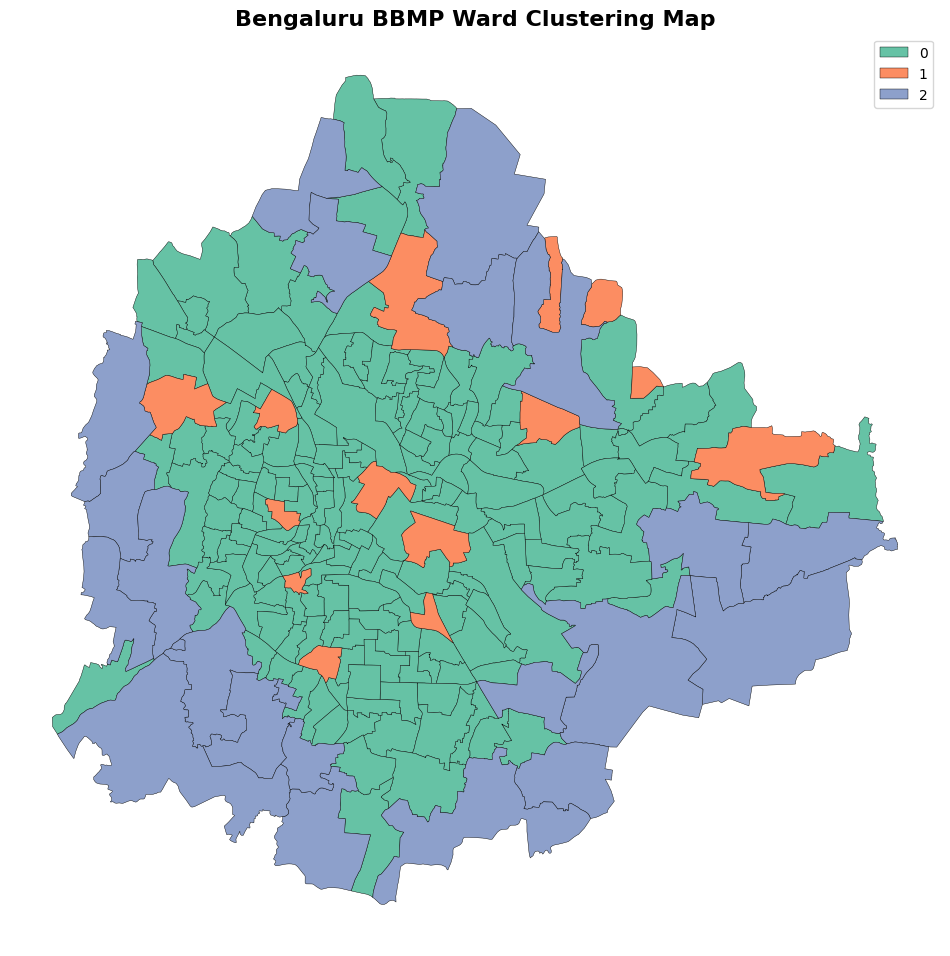

In [28]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 12))

wards_map.plot(
    column='Cluster',
    categorical=True,
    legend=True,
    cmap='Set2',
    edgecolor='black',
    linewidth=0.3,
    ax=ax
)

ax.set_title(
    'Bengaluru BBMP Ward Clustering Map',
    fontsize=16,
    fontweight='bold'
)

ax.set_axis_off()

plt.show()

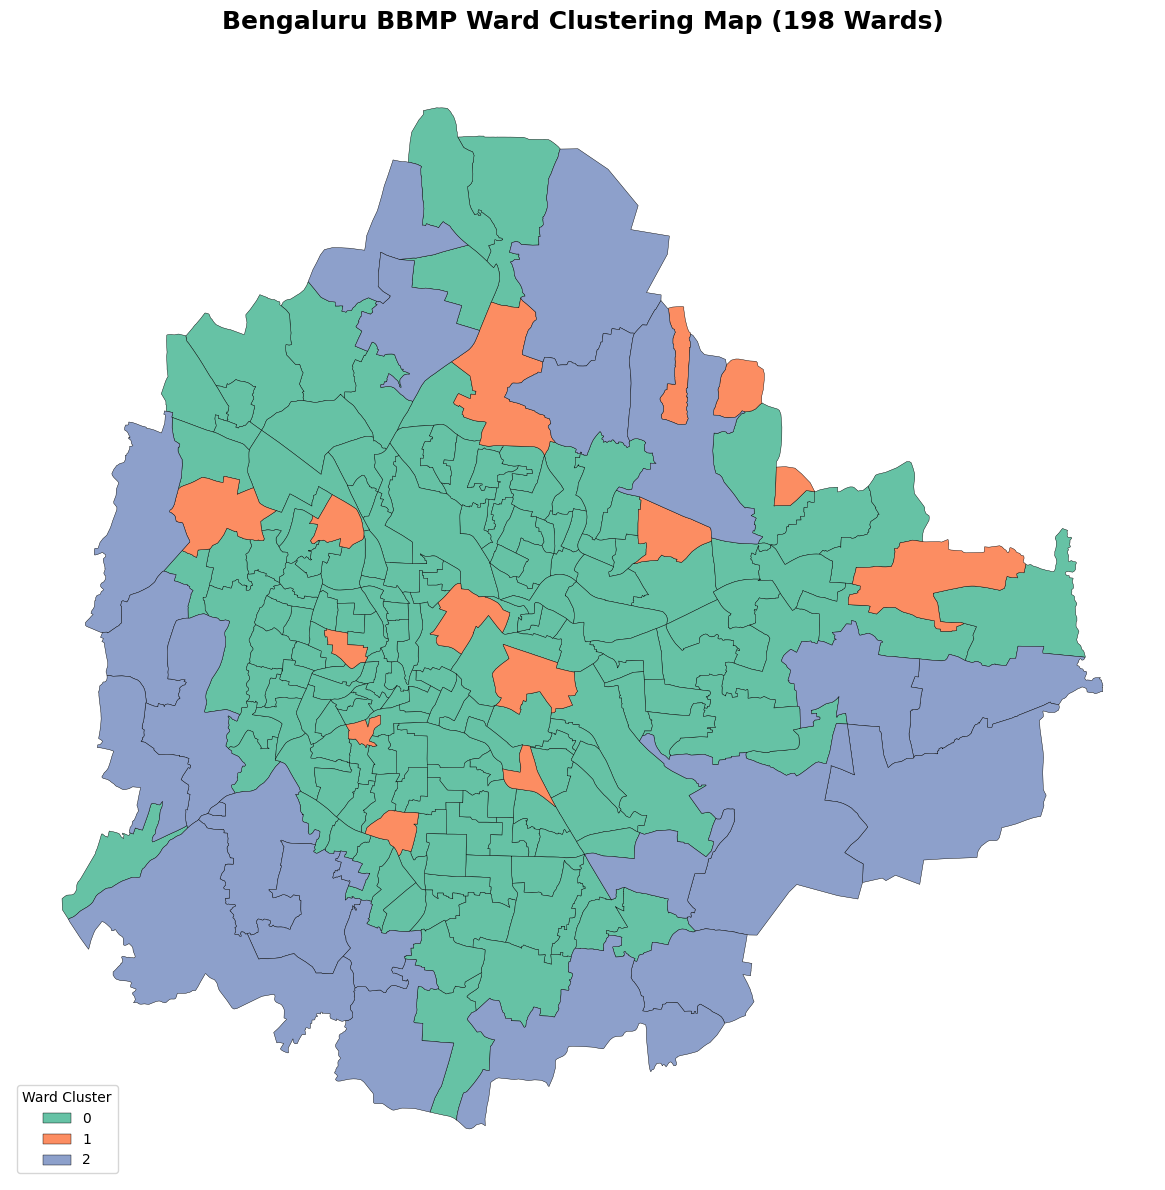

In [29]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 12))

wards_map.plot(
    column='Cluster',
    categorical=True,
    cmap='Set2',
    edgecolor='black',
    linewidth=0.3,
    legend=True,
    legend_kwds={
        'loc': 'lower left',
        'title': 'Ward Cluster'
    },
    ax=ax
)

ax.set_title(
    'Bengaluru BBMP Ward Clustering Map (198 Wards)',
    fontsize=18,
    fontweight='bold',
    pad=20
)

ax.set_axis_off()

plt.tight_layout()
plt.savefig('Day_22_BBMP_Ward_Cluster_Map.png', dpi=300, bbox_inches='tight')
plt.show()

In [30]:
key_messages = [
    "1. Cluster 0 contains 166 wards and has the highest average population density of 30,961 persons per sq km.",

    "2. Cluster 2 contains 21 wards and has the highest average counts of parks, lakes, government schools and playgrounds.",

    "3. Cluster 1 contains 11 wards, with an average population density of 17,311 persons per sq km."
]

print("THREE KEY FINDINGS – BENGALURU WARD STORY\n")

for message in key_messages:
    print(message)
    print()

THREE KEY FINDINGS – BENGALURU WARD STORY

1. Cluster 0 contains 166 wards and has the highest average population density of 30,961 persons per sq km.

2. Cluster 2 contains 21 wards and has the highest average counts of parks, lakes, government schools and playgrounds.

3. Cluster 1 contains 11 wards, with an average population density of 17,311 persons per sq km.



In [31]:
import json

geojson_data = json.loads(wards_map.to_json())

print("GeoJSON features:", len(geojson_data['features']))
print("Map data prepared successfully!")

GeoJSON features: 198
Map data prepared successfully!


In [32]:
print("Available map properties:")
print(geojson_data['features'][0]['properties'].keys())

print("\nSample ward details:")
print(geojson_data['features'][0]['properties'])

Available map properties:
dict_keys(['id', 'Name', 'description', 'timestamp', 'begin', 'end', 'altitudeMode', 'tessellate', 'extrude', 'visibility', 'drawOrder', 'icon', 'Ward_Name', 'Zone', 'Division', 'Subdivision', 'Assembly__MLA__Constituency_', 'Parliament__MP__Constituency', 'Ward_Name_Clean', 'Cluster'])

Sample ward details:
{'id': None, 'Name': 'Ward\xa01', 'description': 'Ward Name: Kempegowda Ward<br>Zone: Yelahanka<br>Division: Yelahanka<br>Subdivision: Yelahanka<br>Assembly (MLA) Constituency : Yelahanka<br>Parliament (MP) Constituency: Chikballapur', 'timestamp': None, 'begin': None, 'end': None, 'altitudeMode': None, 'tessellate': -1, 'extrude': 0, 'visibility': -1, 'drawOrder': None, 'icon': None, 'Ward_Name': 'Kempegowda Ward', 'Zone': 'Yelahanka', 'Division': 'Yelahanka', 'Subdivision': 'Yelahanka', 'Assembly__MLA__Constituency_': 'Yelahanka', 'Parliament__MP__Constituency': 'Chikballapur', 'Ward_Name_Clean': 'kempegowda ward', 'Cluster': 0}


In [33]:
map_df = wards_map[
    ['Ward_Name_Clean', 'Ward_Name', 'Zone', 'Cluster']
].copy()

fig = px.choropleth_mapbox(
    map_df,
    geojson=geojson_data,
    locations='Ward_Name_Clean',
    featureidkey='properties.Ward_Name_Clean',
    color='Cluster',
    hover_name='Ward_Name',
    hover_data=['Zone', 'Cluster'],
    center={'lat': 12.9716, 'lon': 77.5946},
    zoom=9,
    opacity=0.6,
    mapbox_style='carto-positron',
    title='Interactive Bengaluru BBMP Ward Cluster Map'
)

fig.update_layout(
    height=750,
    margin={'r': 0, 't': 60, 'l': 0, 'b': 0}
)

fig.show()

In [34]:
fig.write_html(
    "Day_22_Bengaluru_Interactive_Ward_Map.html"
)

print("Interactive map saved successfully!")

Interactive map saved successfully!


In [35]:
from IPython.display import display, HTML

print("Charts available for the visual story:")
print("1. Ward distribution by cluster")
print("2. Average facilities across clusters")
print("3. Average population across clusters")
print("4. Ward distribution across BBMP zones")
print("5. Top 10 wards by parks")
print("6. Cluster distribution across BBMP zones")
print("7. Average population density across clusters")
print("8. Top 10 wards by population density")

Charts available for the visual story:
1. Ward distribution by cluster
2. Average facilities across clusters
3. Average population across clusters
4. Ward distribution across BBMP zones
5. Top 10 wards by parks
6. Cluster distribution across BBMP zones
7. Average population density across clusters
8. Top 10 wards by population density


In [36]:
chart_names = [
    'cluster_counts',
    'facility_avg',
    'population_avg',
    'zone_counts',
    'top_parks',
    'zone_cluster',
    'density_avg',
    'top_density'
]

for name in chart_names:
    print(name, ":", "Available" if name in globals() else "Not found")

cluster_counts : Available
facility_avg : Available
population_avg : Available
zone_counts : Available
top_parks : Available
zone_cluster : Available
density_avg : Available
top_density : Available


In [39]:
print("Zone counts:")
print(zone_counts.head())
print("\nZone counts columns:")
print(zone_counts.dtypes)

print("\nOther chart data:")
print("Top parks:", top_parks.columns.tolist())
print("Zone cluster:", zone_cluster.columns.tolist())
print("Top density:", top_density.columns.tolist())

Zone counts:
      BBMP Zone  Number of Wards
0         South               53
1          East               44
2          West               35
3  Mahadevapura               17
4  Bommanahalli               16

Zone counts columns:
BBMP Zone          object
Number of Wards     int64
dtype: object

Other chart data:
Top parks: ['Ward Name', 'BBMP Zone Name', 'Parks #']
Zone cluster: ['BBMP Zone Name', 'Cluster', 'Number of Wards']
Top density: ['Ward Name', 'BBMP Zone Name', 'Population density 2011 (persons / sq km)']


In [40]:
import plotly.express as px

chart_figures = [
    ("Ward Distribution by Cluster",
     px.bar(cluster_counts, x="Cluster", y="Number of Wards")),

    ("Average Facilities Across Clusters",
     px.bar(facility_avg, x="Cluster", barmode="group")),

    ("Average Population Across Clusters",
     px.bar(population_avg, x="Cluster")),

    ("Ward Distribution Across BBMP Zones",
     px.bar(zone_counts, x="BBMP Zone", y="Number of Wards")),

    ("Top 10 Wards by Parks",
     px.bar(top_parks, x="Ward Name", y="Parks #")),

    ("Cluster Distribution Across BBMP Zones",
     px.bar(zone_cluster, x="BBMP Zone Name",
            y="Number of Wards", color="Cluster", barmode="group")),

    ("Average Population Density Across Clusters",
     px.bar(density_avg, x="Cluster")),

    ("Top 10 Wards by Population Density",
     px.bar(top_density, x="Ward Name",
            y="Population density 2011 (persons / sq km)"))
]

print("All eight chart figures created successfully!")

All eight chart figures created successfully!


In [41]:
import plotly.io as pio

# Convert all charts into HTML
html_parts = []

for title, chart in chart_figures:
    chart_html = pio.to_html(
        chart,
        full_html=False,
        include_plotlyjs=False
    )
    html_parts.append(
        f"<section><h2>{title}</h2>{chart_html}</section>"
    )

# Convert interactive map
map_html = pio.to_html(
    fig,
    full_html=False,
    include_plotlyjs=False
)

# Three key findings
messages_html = """
<section>
<h2>Three Key Findings</h2>
<ol>
<li>Cluster 0 contains 166 wards and has the highest average population density
of approximately 30,961 persons per sq km.</li>
<li>Cluster 2 contains 21 wards and has the highest average counts of parks,
lakes, government schools and playgrounds.</li>
<li>Cluster 1 contains 11 wards, with an average population density of
approximately 17,311 persons per sq km.</li>
</ol>
</section>
"""

# Build complete visual story
final_html = f"""
<html>
<head>
<title>Bengaluru BBMP Ward Visual Story</title>
<script src="https://cdn.plot.ly/plotly-2.35.2.min.js"></script>
<style>
body {{
    font-family: Arial, sans-serif;
    margin: 30px;
    background: #f3f5f7;
}}
h1, h2 {{ color: #183153; }}
section {{
    background: white;
    padding: 20px;
    margin-bottom: 25px;
    border-radius: 10px;
}}
</style>
</head>
<body>

<h1>Bengaluru BBMP Ward Visual Story</h1>
<p>Data analysis of 198 BBMP wards using clustering,
public facilities and population density.</p>

<section>
<h2>Interactive Bengaluru Ward Cluster Map</h2>
{map_html}
</section>

{messages_html}

{''.join(html_parts)}

</body>
</html>
"""

with open("Day_22_Bengaluru_Ward_Visual_Story.html",
          "w", encoding="utf-8") as file:
    file.write(final_html)

print("Complete visual story HTML created successfully!")

Complete visual story HTML created successfully!


In [42]:
import os

file_name = "Day_22_Bengaluru_Ward_Visual_Story.html"

print("File exists:", os.path.exists(file_name))
print("File size:", round(os.path.getsize(file_name) / 1024, 2), "KB")

File exists: True
File size: 1262.31 KB


In [44]:
from google.colab import files

files.download("Day_22_Bengaluru_Ward_Visual_Story.html")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [45]:
from google.colab import files

files.download("Day_22_BBMP_Ward_Cluster_Map.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>